In [89]:
import pandas as  pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,classification_report,confusion_matrix
)

In [90]:
df=pd.read_csv("mushrooms.csv")

In [91]:
print(df.info())
print("\n First 5 lines:")
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

In [92]:
print("\n Column names: \n",df.columns.tolist())


 Column names: 
 ['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']


In [93]:
print("\n Target Distribution: \n")
print(df["class"].value_counts())


 Target Distribution: 

class
e    4208
p    3916
Name: count, dtype: int64


In [94]:
print("\n Missing values per column:")
print(df.isnull().sum())


 Missing values per column:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


In [95]:
df.replace("?",np.nan,inplace=True)
df.fillna(df.mode().iloc[0],inplace=True)
print("\n After cleaning - missing values:")
print(df.isnull().sum())


 After cleaning - missing values:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64


In [96]:
encoders={}
le=LabelEncoder()

for col in df.columns:
    df[col]=le.fit_transform(df[col])

print("\n After encoding first 5 rows: \n")
print(df.head())


 After encoding first 5 rows: 

   class  cap-shape  cap-surface  cap-color  bruises  odor  gill-attachment  \
0      1          5            2          4        1     6                1   
1      0          5            2          9        1     0                1   
2      0          0            2          8        1     3                1   
3      1          5            3          8        1     6                1   
4      0          5            2          3        0     5                1   

   gill-spacing  gill-size  gill-color  ...  stalk-surface-below-ring  \
0             0          1           4  ...                         2   
1             0          0           4  ...                         2   
2             0          0           5  ...                         2   
3             0          1           5  ...                         2   
4             1          0           4  ...                         2   

   stalk-color-above-ring  stalk-color-below-ring  ve

In [97]:
x= df.drop("class",axis=1)
y=df["class"]

print("\n Features value:",x.shape)
print("\n Target shape:",y.shape)
print("\n Target values:",y.unique())


 Features value: (8124, 22)

 Target shape: (8124,)

 Target values: [1 0]


In [98]:
x_train,x_test,y_train,y_test= train_test_split(
    x,y,test_size=0.2,random_state=42
)

In [99]:
rf_model=RandomForestClassifier(
n_estimators=100,
max_depth=None,
random_state=42,
n_jobs=-1
)
rf_model.fit(x_train,y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [100]:
y_pred=rf_model.predict(x_test)

In [101]:
accuracy=accuracy_score(y_test,y_pred)
print(accuracy)

1.0


In [102]:
print(classification_report(y_test,y_pred,target_names=["Edible","Poisonous"]))

              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       843
   Poisonous       1.00      1.00      1.00       782

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [103]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[843   0]
 [  0 782]]


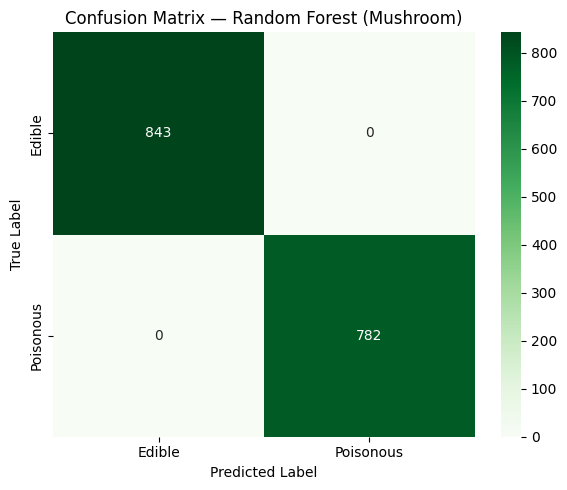

✅ Confusion matrix saved as confusion_matrix.png


In [104]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,           # Show numbers inside boxes
    fmt="d",              # Integer format
    cmap="Greens",        # Color theme
    xticklabels=["Edible", "Poisonous"],
    yticklabels=["Edible", "Poisonous"]
)
plt.title("Confusion Matrix — Random Forest (Mushroom)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print("✅ Confusion matrix saved as confusion_matrix.png")

In [105]:
importances=rf_model.feature_importances_
feature_names=x.columns.tolist()

feat_df=pd.DataFrame({
    "Feature":feature_names,
    "Importance":importances
}).sort_values("Importance",ascending=False)

In [106]:
print("\n Top 10 most important features:")
print(feat_df.head(10).to_string(index=False))


 Top 10 most important features:
                 Feature  Importance
                    odor    0.170572
               gill-size    0.121913
              gill-color    0.115072
       spore-print-color    0.102634
               ring-type    0.064373
              population    0.062443
stalk-surface-above-ring    0.056446
                 bruises    0.052025
              stalk-root    0.049386
stalk-surface-below-ring    0.030972


C:\Users\Aun Abbas\AppData\Local\Temp\ipykernel_19684\113391792.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


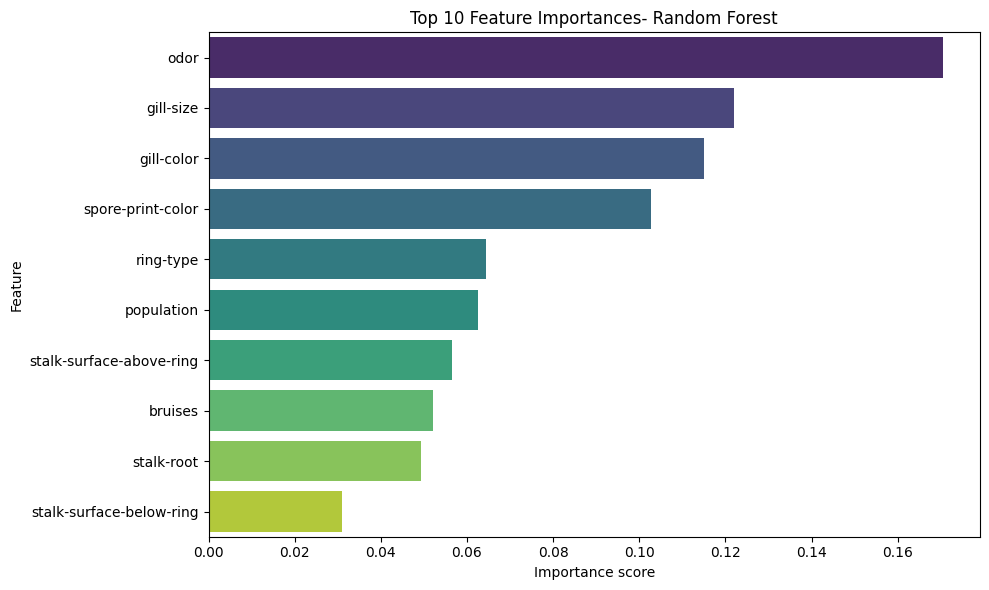

In [107]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=feat_df.head(10),
    x="Importance",
    y="Feature",
    palette="viridis"
)
plt.title("Top 10 Feature Importances- Random Forest")
plt.xlabel("Importance score")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("feature_importance.png",dpi=150)
plt.show()

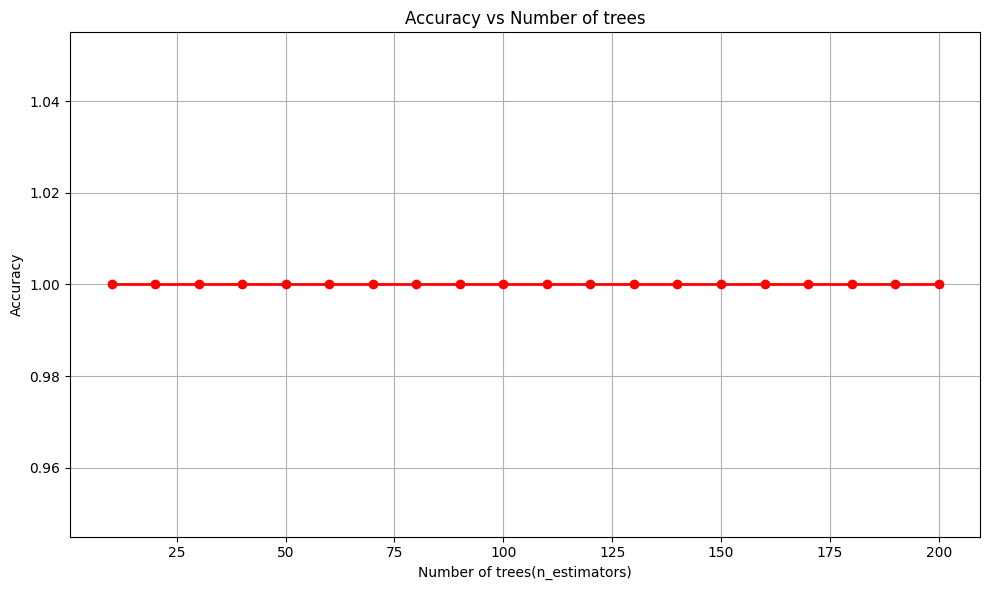

In [108]:
tree_counts=list(range(10,201,10))
accuracies=[]

for n in tree_counts:
    model=RandomForestClassifier(n_estimators=n,random_state=42,n_jobs=-1)
    model.fit(x_train,y_train)
    preds=model.predict(x_test)
    accuracies.append(accuracy_score(y_test,y_pred))

plt.figure(figsize=(10,6))
plt.plot(tree_counts,accuracies,marker="o",color="red",linewidth=2)
plt.title("Accuracy vs Number of trees")
plt.xlabel("Number of trees(n_estimators)")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy_vs_trees.png",dpi=150)
plt.show()

In [109]:
model_data ={
    "model": rf_model,
    "encoders": encoders,
    "features": x.columns.tolist()
}

pkl_path ="mushroom_rf_model.pkl"

with open(pkl_path, "wb") as f:
    pickle.dump(model_data,f)